# Stochastic Rounding Simulations for Ternary Quantization

This notebook provides a pure numeric simulation mapping out how **Stochastic Rounding** alters the transfer threshold boundary curves of ultra-low bitwidth **Ternary Quantizers**.

### Core Algorithmic Concepts Shown in This Example

* **Ternary State Quantization Thresholds:** Standard ternary operators compress full-precision continuous weights down to exactly three discrete numerical choices: $\{-1, 0, 1\}$ by establishing a hard threshold barrier ($T$). Values falling between $[-T, T]$ are aggressively zeroed out, while external values are clamped to their respective polar signs.
* **Stochastic Boundary Smoothing:** Instead of using rigid deterministic cutoff lines, this algorithm samples from a continuous uniform random distribution `np.random.uniform(0, 1)`. Near the quantization decision threshold boundaries, weights have a statistical probability of rounding up or down depending on how close they are to the barrier. Running this over multiple iterations transforms rough, step-like step transformations into a smooth, continuous probabilistic curve, preserving small updates during training.

### 1. Environment Setup & Dependency Installation
Uncomment the cell below if you need to install the required libraries inside your runtime environment.

In [1]:
# !pip install qkeras-v3 keras tensorflow matplotlib

### 2. Configure Visualization Backend and Rounding Functions

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import keras.ops.numpy as knp

def _stochastic_rounding(x, precision, resolution, delta):
    """Performs probabilistic stochastic rounding transitions along boundary regions."""
    delta_left = delta - precision
    delta_right = delta + precision
    scale = 1 / resolution
    scale_delta_left = delta_left * scale
    scale_delta_right = delta_right * scale
    scale_2_delta = scale_delta_right - scale_delta_left
    scale_x = x * scale
    fraction = scale_x - scale_delta_left

    # Generate probabilistic uniform array mapping
    random_selector = np.random.uniform(0, 1, size=x.shape) * scale_2_delta

    result = knp.where(
        fraction < random_selector, scale_delta_left / scale, scale_delta_right / scale
    )
    return result

def _ternary(x, sto=False):
    """Maps values to ternary values {-1, 0, 1}, optionally applying stochastic boundaries."""
    m = knp.amax(knp.abs(x), keepdims=True)
    scale = 2 * m / 3.0
    thres = scale / 2.0

    if sto:
        sign_bit = knp.sign(x)
        x = knp.abs(x)
        x = (
            sign_bit
            * scale
            * _stochastic_rounding(
                x / scale,
                precision=0.3,
                resolution=0.01,
                delta=thres / scale,
            )
        )
    return knp.where(knp.abs(x) < thres, knp.zeros_like(x), knp.sign(x))

/Users/mariuskoppel/cms/qkeras/venv/lib/python3.11/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


### 3. Run Monte Carlo Statistical Simulations & View Curves

Simulating 500 sampling iterations over step distributions...


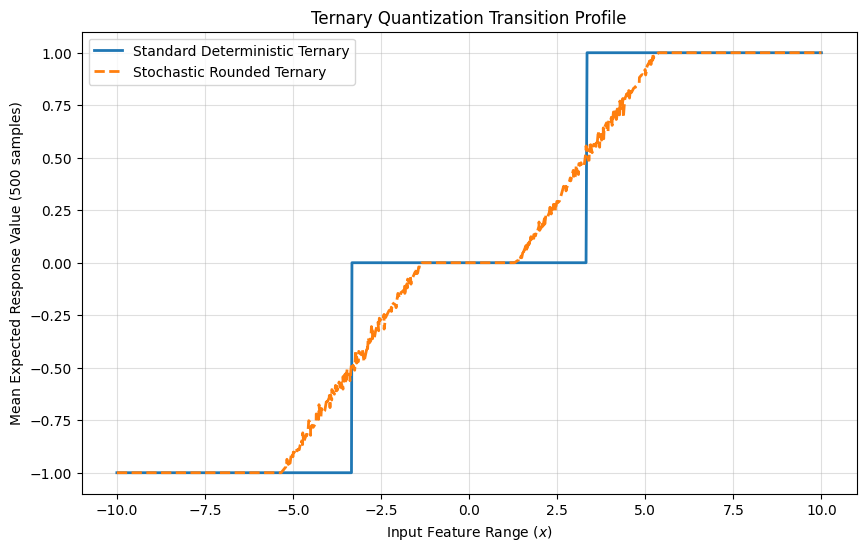

In [3]:
# Generate uniformly distributed test values
x = np.random.uniform(-10.0, 10.0, size=1000)
x = knp.sort(x)

tr = knp.zeros_like(x)
t = knp.zeros_like(x)
iter_count = 500

print(f"Simulating {iter_count} sampling iterations over step distributions...")
for _ in range(iter_count):
    y = _ternary(x, sto=False)
    yr = _ternary(x, sto=True)
    t = t + y
    tr = tr + yr

# Display plot mappings
plt.figure(figsize=(10, 6))
plt.plot(x, t / iter_count, label="Standard Deterministic Ternary", linewidth=2)
plt.plot(x, tr / iter_count, label="Stochastic Rounded Ternary", linestyle="--", linewidth=2)
plt.xlabel("Input Feature Range ($x$)")
plt.ylabel(f"Mean Expected Response Value ({iter_count} samples)")
plt.title("Ternary Quantization Transition Profile")
plt.grid(True, alpha=0.4)
plt.legend(loc="upper left")
plt.show()